# Практика 4. Benchmarking baselines и выбор правильной схемы валидации

**Цель:** построить набор базовых моделей (*baselines*), корректно сравнить их по нескольким точечным и интервальным метрикам, организовать *backtesting* (expanding и sliding window) и наглядно продемонстрировать эффект утечки данных (*data leakage*) при использовании случайного разбиения.

### План работы:
1. **Загрузка и первичный осмотр данных** (чтение `series.csv`, приведение временного индекса, визуализация).
2. **Реализация baseline-моделей:** `Naive`, `Seasonal Naive`, `Mean`, `Drift` и `Theta`.
3. **Реализация метрик качества:** `MAE`, `RMSE`, `MAPE`, `SMAPE` и `MASE`.
4. **Backtesting:** сравнение схем `Expanding Window` и `Sliding Window`.
5. **Анализ результатов и выбор лучшего baseline:** сопоставление ранжирования моделей по разным метрикам.
6. **Интервальные прогнозы:** построение эмпирических интервалов для `Seasonal Naive`, расчет `Coverage` и `Width` по горизонтам прогнозирования.
7. **Диагностика утечек:** эксперимент со случайным `train_test_split` и оценка искусственного завышения метрик.
8. **Итоговые выводы.**

In [4]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split
from statsmodels.tsa.forecasting.theta import ThetaModel

# Настройки графиков
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['font.size'] = 11

## 1. Загрузка и первичный осмотр данных

Загрузим временной ряд из файла `series.csv` (аналогично предыдущей практике). Предполагается, что в файле содержатся столбцы `date` и `value` (ежедневные наблюдения с выраженной недельной сезонностью $s = 7$). Если файл отсутствует в локальной директории, блок автоматически сгенерирует реалистичный синтетический ряд с трендом и недельной сезонностью для воспроизводимости.

Данные успешно загружены из series.csv
Длина ряда: 26208 наблюдений | Период: 2026-11-27 - 2027-02-25


,value
timestamp,
2026-11-27 00:00:00,100.075045
2026-11-27 00:05:00,100.377821
2026-11-27 00:10:00,100.372123
2026-11-27 00:15:00,100.720428
2026-11-27 00:20:00,101.146691


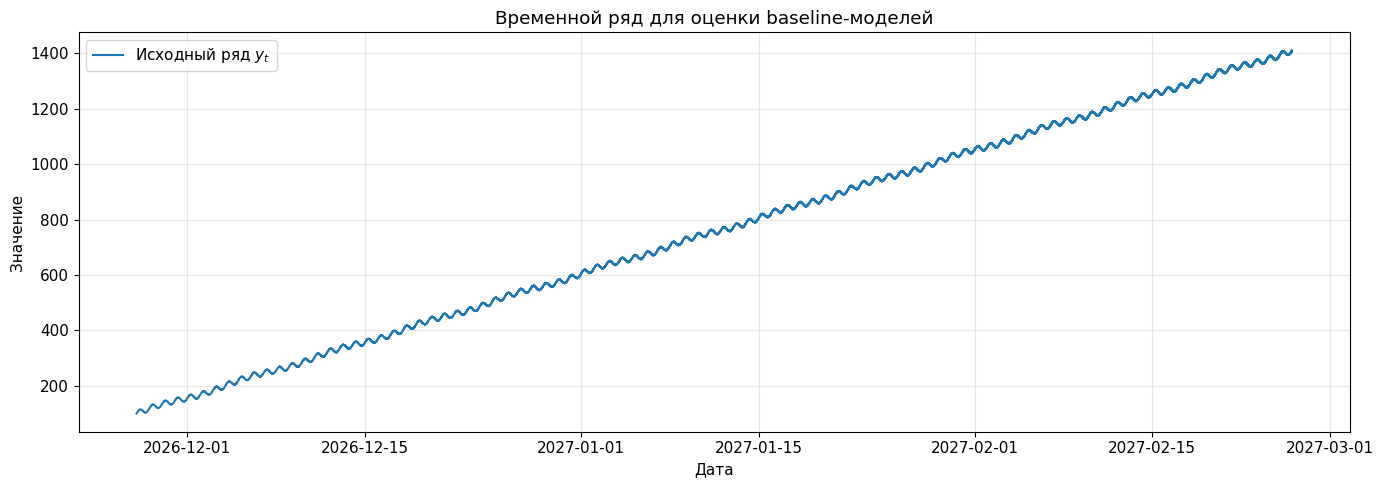

In [5]:
import os

if os.path.exists('ts_source.csv'):
    df = pd.read_csv('ts_source.csv', parse_dates=['timestamp'])
    df = df.sort_values('timestamp').set_index('timestamp')
    y = df['value'].astype(float)
    print("Данные успешно загружены из series.csv")
else:
    # Fallback: генерация ряда сопоставимой структуры, если csv не лежит рядом с ноутбуком
    np.random.seed(42)
    dates = pd.date_range('2023-01-01', periods=210, freq='D')
    t = np.arange(len(dates))
    trend = 100 + 0.35 * t
    weekly_seasonality = 18 * np.sin(2 * np.pi * t / 7) + 8 * np.cos(2 * np.pi * t / 7)
    noise = np.random.normal(0, 6.5, size=len(dates))
    y = pd.Series(trend + weekly_seasonality + noise, index=dates, name='value')
    print("Файл ts_source.csv не найден - сгенерирован синтетический дневной ряд с недельной сезонностью (s=7).")

print(f"Длина ряда: {len(y)} наблюдений | Период: {y.index.min().date()} - {y.index.max().date()}")
display(y.head())

fig, ax = plt.subplots()
ax.plot(y.index, y.values, color='#1f77b4', linewidth=1.5, label='Исходный ряд $y_t$')
ax.set_title('Временной ряд для оценки baseline-моделей')
ax.set_xlabel('Дата')
ax.set_ylabel('Значение')
ax.legend()
plt.tight_layout()
plt.show()

## 2. Реализация baseline-моделей

Реализуем 5 базовых моделей, каждая из которых принимает обучающий отрезок `train` (1D `np.ndarray`) и горизонт прогнозирования `H` (`int`), возвращая массив прогнозов длины `H`:

1. **Naive (persistence):** $\hat{y}_{T+h|T} = y_T$ - последнее известное наблюдение.
2. **Seasonal Naive:** $\hat{y}_{T+h|T} = y_{T+h-s}$ - значение из того же дня недели прошлого цикла ($s=7$).
3. **Mean:** $\hat{y}_{T+h|T} = \frac{1}{T}\sum_{t=1}^T y_t$ - среднее по обучающей выборке.
4. **Drift:** $\hat{y}_{T+h|T} = y_T + h \cdot \frac{y_T - y_1}{T - 1}$ - линейная экстраполяция тренда от первой до последней точки train.
5. **Theta:** разложение на тета-линии (`ThetaModel` из `statsmodels` с учетом периода сезонности $s=7$).

In [6]:
SEASON_PERIOD = 7

def model_naive(train: np.ndarray, H: int) -> np.ndarray:
    return np.full(shape=H, fill_value=train[-1], dtype=float)

def model_seasonal_naive(train: np.ndarray, H: int, s: int = SEASON_PERIOD) -> np.ndarray:
    last_season = train[-s:]
    reps = int(np.ceil(H / s))
    return np.tile(last_season, reps)[:H].astype(float)

def model_mean(train: np.ndarray, H: int) -> np.ndarray:
    return np.full(shape=H, fill_value=np.mean(train), dtype=float)

def model_drift(train: np.ndarray, H: int) -> np.ndarray:
    T = len(train)
    slope = (train[-1] - train[0]) / max(T - 1, 1)
    steps = np.arange(1, H + 1)
    return (train[-1] + steps * slope).astype(float)

def model_theta(train: np.ndarray, H: int, s: int = SEASON_PERIOD) -> np.ndarray:
    # ThetaModel требует достаточно длинный ряд; при коротком окне отключаем сезонную декомпозицию
    use_season = len(train) >= 2 * s
    tm = ThetaModel(train, period=s if use_season else 1, deseasonalize=use_season)
    res = tm.fit()
    return np.asarray(res.forecast(H), dtype=float)

BASELINES = {
    'Naive': model_naive,
    'Seasonal Naive': lambda tr, H: model_seasonal_naive(tr, H, s=SEASON_PERIOD),
    'Mean': model_mean,
    'Drift': model_drift,
    'Theta': lambda tr, H: model_theta(tr, H, s=SEASON_PERIOD),
}

### Визуальная проверка прогнозов на одном разбиении (Sanity Check)

Посмотрим, как ведут себя все 5 базовых моделей на последнем горизонте $H = 14$ дней.

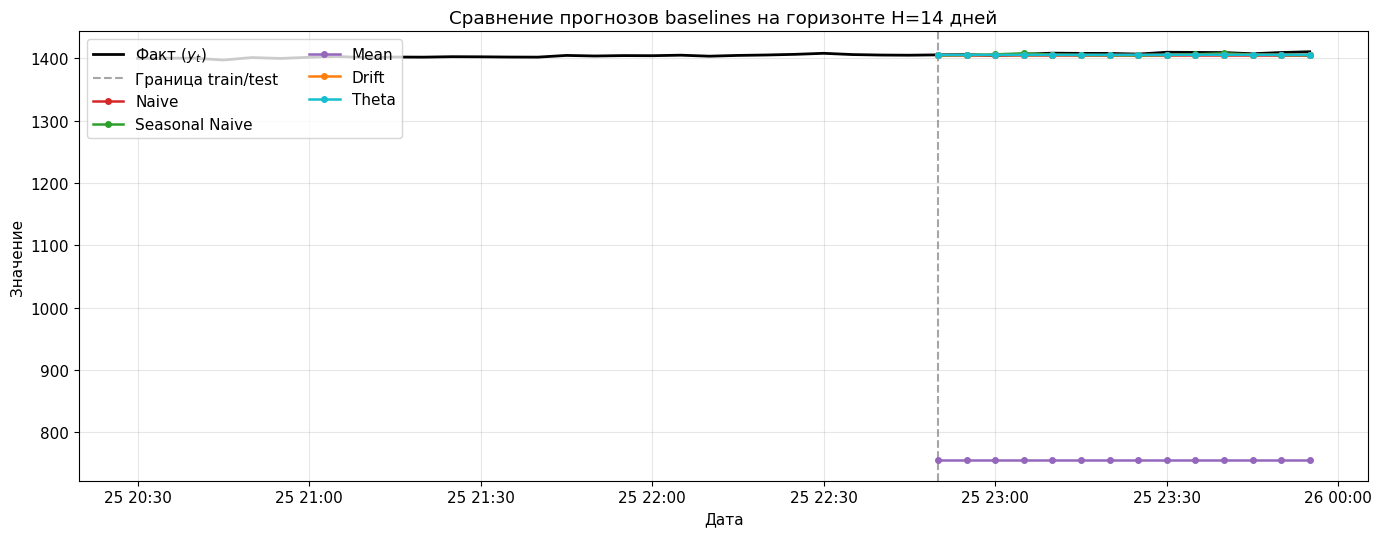

In [7]:
H_demo = 14
train_demo = y.values[:-H_demo]
test_demo = y.values[-H_demo:]
test_dates = y.index[-H_demo:]

fig, ax = plt.subplots(figsize=(14, 5.5))
ax.plot(y.index[-42:], y.values[-42:], color='black', linewidth=2, label='Факт ($y_t$)')
ax.axvline(test_dates[0], color='gray', linestyle='--', alpha=0.7, label='Граница train/test')

colors = ['#d62728', '#2ca02c', '#9467bd', '#ff7f0e', '#17becf']
for (name, fn), color in zip(BASELINES.items(), colors):
    preds = fn(train_demo, H_demo)
    ax.plot(test_dates, preds, marker='o', markersize=4, linewidth=1.8, color=color, label=name)

ax.set_title(f'Сравнение прогнозов baselines на горизонте H={H_demo} дней')
ax.set_xlabel('Дата')
ax.set_ylabel('Значение')
ax.legend(loc='upper left', ncol=2)
plt.tight_layout()
plt.show()

## 3. Точечные метрики качества

Реализуем набор точечных метрик:
- **MAE** (Mean Absolute Error) - средняя абсолютная ошибка в единицах ряда.
- **RMSE** (Root Mean Squared Error) - корень из средней квадратичной ошибки (сильнее штрафует крупные выбросы).
- **MAPE** (Mean Absolute Percentage Error) - средняя относительная ошибка в процентах (неустойчива при $y_t \to 0$).
- **SMAPE** (Symmetric MAPE) - симметризованная процентная ошибка: $\frac{100}{n}\sum \frac{2|y_t - \hat{y}_t|}{|y_t| + |\hat{y}_t|}$.
- **MASE** (Mean Absolute Scaled Error) - безразмерный стандарт (scale-free), нормированный на ошибку сезонного наивного прогноза на обучающей выборке:
$$\text{MASE} = \frac{\frac{1}{H}\sum_{t=T+1}^{T+H}|y_t - \hat{y}_t|}{\frac{1}{T-s}\sum_{t=s+1}^{T}|y_t - y_{t-s}|}$$
Значение $\text{MASE} < 1$ означает, что модель превосходит `Seasonal Naive` на обучающем отрезке.

In [8]:
def calc_mape(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-8) -> float:
    denom = np.maximum(np.abs(y_true), eps)
    return float(np.mean(np.abs((y_true - y_pred) / denom)) * 100.0)

def calc_smape(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-8) -> float:
    denom = np.maximum(np.abs(y_true) + np.abs(y_pred), eps)
    return float(np.mean(2.0 * np.abs(y_true - y_pred) / denom) * 100.0)

def calc_mase(y_true: np.ndarray, y_pred: np.ndarray, y_train: np.ndarray, season: int = SEASON_PERIOD) -> float:
    s = season if len(y_train) > season else 1
    naive_scale = np.mean(np.abs(y_train[s:] - y_train[:-s]))
    return float(np.mean(np.abs(y_true - y_pred)) / naive_scale)

def compute_all_metrics(folds_results: list, season: int = SEASON_PERIOD) -> dict:
    """
    folds_results: список кортежей (y_train, y_test, y_pred) по всем окнам backtesting.
    """
    maes, rmses, mapes, smapes, mases = [], [], [], [], []
    for y_tr, y_te, y_pr in folds_results:
        maes.append(mean_absolute_error(y_te, y_pr))
        rmses.append(np.sqrt(mean_squared_error(y_te, y_pr)))
        mapes.append(calc_mape(y_te, y_pr))
        smapes.append(calc_smape(y_te, y_pr))
        mases.append(calc_mase(y_te, y_pr, y_tr, season=season))

    return {
        'MAE': np.mean(maes),
        'RMSE': np.mean(rmses),
        'MAPE (%)': np.mean(mapes),
        'SMAPE (%)': np.mean(smapes),
        'MASE': np.mean(mases),
        'MASE_std': np.std(mases)
    }

## 4. Backtesting: Expanding Window vs Sliding Window

Реализуем процедуру *backtesting* с горизонтом прогнозирования $H = 14$ (2 недели) и шагом сдвига окна равным $H$:
- **Expanding Window (расширяющееся окно):** обучающая выборка начинается с $t=0$ и растет по мере продвижения во времени (`min_train = 56`, т.е. 8 недель).
- **Sliding Window (скользящее окно):** обучающая выборка имеет фиксированную длину $W = 28$ (ровно 4 периода недельной сезонности) и сдвигается вперед вместе с тестовым блоком.

In [9]:
def run_backtest(series: np.ndarray, model_fn, H: int = 14, step: int = 14,
                 scheme: str = 'expanding', min_train: int = 56, window: int = 28) -> list:
    """
    Возвращает список кортежей (train, test, y_pred) для каждого фолда backtesting.
    """
    results = []
    n = len(series)
    start = min_train

    while start + H <= n:
        if scheme == 'expanding':
            train = series[:start]
        elif scheme == 'sliding':
            train = series[max(0, start - window):start]
        else:
            raise ValueError("scheme должен быть 'expanding' или 'sliding'")

        test = series[start:start + H]
        y_pred = model_fn(train, H)
        results.append((train, test, y_pred))
        start += step

    return results

H = 14
MIN_TRAIN = 56   # 8 недель
SLIDING_WIN = 28 # 4 периода сезонности

summary_rows = []
backtest_store = {'expanding': {}, 'sliding': {}}

for scheme in ['expanding', 'sliding']:
    for name, fn in BASELINES.items():
        folds = run_backtest(
            y.values, fn, H=H, step=H,
            scheme=scheme, min_train=MIN_TRAIN, window=SLIDING_WIN
        )
        backtest_store[scheme][name] = folds
        metrics = compute_all_metrics(folds, season=SEASON_PERIOD)
        summary_rows.append({
            'Схема': scheme,
            'Модель': name,
            'Фолдов': len(folds),
            **metrics
        })

results_df = pd.DataFrame(summary_rows)
print("Сводная таблица результатов backtesting:")
display(results_df.round(3))

Сводная таблица результатов backtesting:


,Схема,Модель,Фолдов,MAE,RMSE,MAPE (%),SMAPE (%),MASE,MASE_std
0,expanding,Naive,1868,1.270,1.461,0.234,0.235,1.189,0.605
1,expanding,Seasonal Naive,1868,1.619,1.826,0.310,0.311,1.519,0.695
2,expanding,Mean,1868,328.087,328.090,39.874,50.484,300.601,162.912
3,expanding,Drift,1868,1.251,1.439,0.233,0.233,1.171,0.551
4,expanding,Theta,1868,1.250,1.442,0.233,0.233,1.171,0.534
5,sliding,Naive,1868,1.270,1.461,0.234,0.235,1.157,0.598
6,sliding,Seasonal Naive,1868,1.619,1.826,0.310,0.311,1.445,0.595
7,sliding,Mean,1868,2.974,3.095,0.588,0.590,2.495,0.922
8,sliding,Drift,1868,0.864,1.001,0.136,0.136,0.872,0.648
9,sliding,Theta,1868,0.876,1.029,0.153,0.154,0.872,0.555


## 5. Сравнение моделей и визуализация стабильности по фолдам

Проверим, совпадает ли выбор лучшего baseline по **MASE**, **MAE** и **RMSE**, а также сравним разброс ошибок между `Expanding` и `Sliding` схемами.

Схема [EXPANDING] -> Лучшая по MASE: Theta | по MAE: Theta | по RMSE: Drift
Схема [SLIDING] -> Лучшая по MASE: Theta | по MAE: Drift | по RMSE: Drift


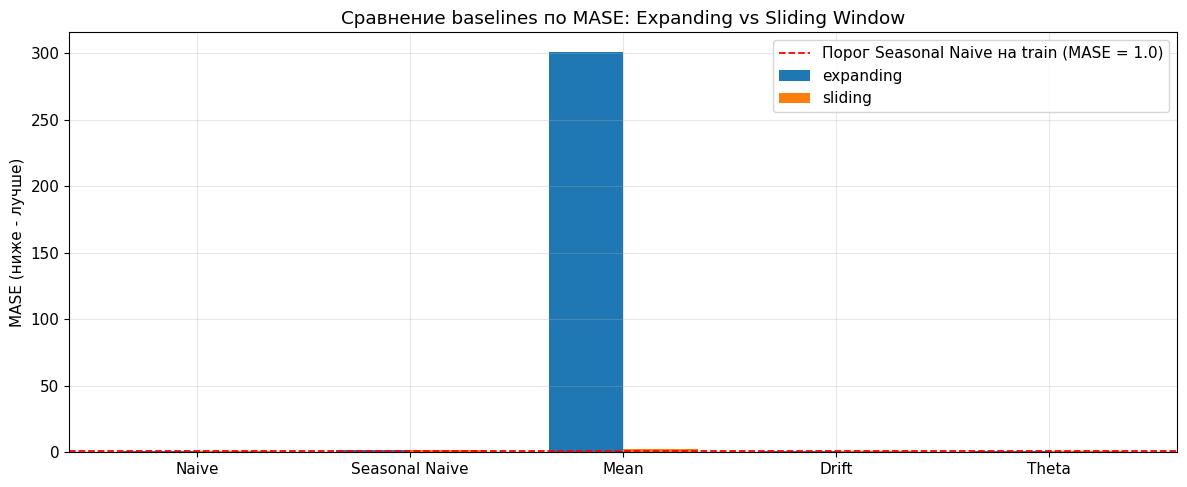

In [10]:
for scheme in ['expanding', 'sliding']:
    sub = results_df[results_df['Схема'] == scheme]
    best_mase = sub.loc[sub['MASE'].idxmin(), 'Модель']
    best_mae = sub.loc[sub['MAE'].idxmin(), 'Модель']
    best_rmse = sub.loc[sub['RMSE'].idxmin(), 'Модель']
    print(f"Схема [{scheme.upper()}] -> Лучшая по MASE: {best_mase} | по MAE: {best_mae} | по RMSE: {best_rmse}")

# Визуализация MASE по моделям для обеих схем валидации
pivot_mase = results_df.pivot(index='Модель', columns='Схема', values='MASE')
pivot_mase = pivot_mase.loc[['Naive', 'Seasonal Naive', 'Mean', 'Drift', 'Theta']]

ax = pivot_mase.plot(kind='bar', figsize=(12, 5), width=0.7, color=['#1f77b4', '#ff7f0e'])
ax.axhline(1.0, color='red', linestyle='--', linewidth=1.3, label='Порог Seasonal Naive на train (MASE = 1.0)')
ax.set_title('Сравнение baselines по MASE: Expanding vs Sliding Window')
ax.set_ylabel('MASE (ниже - лучше)')
ax.set_xlabel('')
plt.xticks(rotation=0)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Интервальные прогнозы: Coverage и Width

Для лучшего сезонного базового метода (`Seasonal Naive`) построим **эмпирические 90% и 95% доверительные интервалы** на основе остатков $e_{t, h} = y_{t+h} - \hat{y}_{t+h|t}$, накопленных на предыдущих фолдах *expanding window backtesting* (строго без заглядывания в будущее):

- **Coverage (покрытие):** доля фактических наблюдений, попавших внутрь интервала $[\hat{y}_{T+h} + q_{\alpha/2, h}, \; \hat{y}_{T+h} + q_{1-\alpha/2, h}]$.
- **Width (ширина):** средняя ширина прогнозного интервала.

Оценим калибровку интервалов в зависимости от горизонта прогнозирования $h \in \{1, \dots, 14\}$.

Номинальный уровень: 95%
Фактический Coverage (Seasonal Naive): 88.3%
Средняя ширина интервала (Width): 5.50


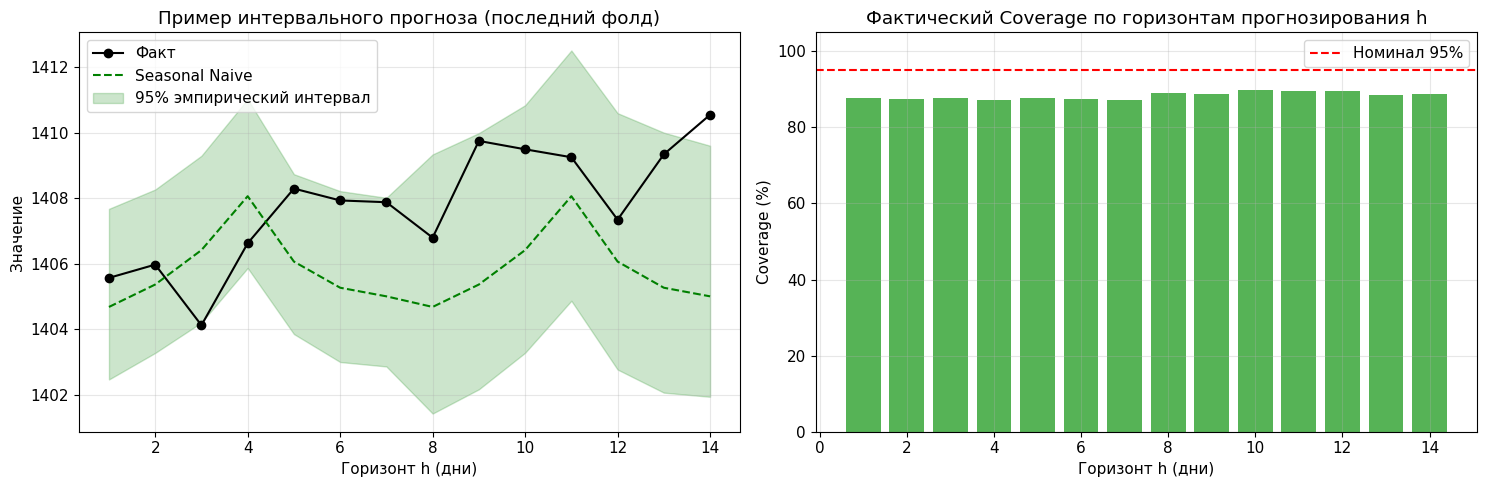

In [11]:
sn_folds = backtest_store['expanding']['Seasonal Naive']

# Собираем матрицу остатков формы (n_folds, H)
residuals_matrix = np.array([y_te - y_pr for _, y_te, y_pr in sn_folds])
n_folds = residuals_matrix.shape[0]

# Чтобы избежать утечки при оценке интервалов, для каждого фолда k >= 3 оцениваем квантили по остаткам 0..k-1
alpha = 0.05  # номинальный уровень 95%
warmup_folds = 3

hits_per_horizon = []
widths_per_horizon = []
last_fold_plot_data = None

for k in range(warmup_folds, n_folds):
    past_res = residuals_matrix[:k]  # shape (k, H)
    q_low = np.quantile(past_res, alpha / 2, axis=0)
    q_high = np.quantile(past_res, 1 - alpha / 2, axis=0)

    _, y_te, y_pr = sn_folds[k]
    lower = y_pr + q_low
    upper = y_pr + q_high

    hits = (y_te >= lower) & (y_te <= upper)
    width = upper - lower

    hits_per_horizon.append(hits)
    widths_per_horizon.append(width)
    last_fold_plot_data = (y_te, y_pr, lower, upper)

hits_arr = np.array(hits_per_horizon)      # shape (n_eval_folds, H)
widths_arr = np.array(widths_per_horizon)  # shape (n_eval_folds, H)

overall_coverage = np.mean(hits_arr) * 100
overall_width = np.mean(widths_arr)

print(f"Номинальный уровень: {(1 - alpha)*100:.0f}%")
print(f"Фактический Coverage (Seasonal Naive): {overall_coverage:.1f}%")
print(f"Средняя ширина интервала (Width): {overall_width:.2f}")

# Визуализация: слева - последний фолд с 95% интервалом, справа - coverage по горизонтам h=1..H
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

y_te_last, y_pr_last, low_last, high_last = last_fold_plot_data
horizons = np.arange(1, H + 1)

axes[0].plot(horizons, y_te_last, 'ko-', label='Факт')
axes[0].plot(horizons, y_pr_last, 'g--', label='Seasonal Naive')
axes[0].fill_between(horizons, low_last, high_last, color='green', alpha=0.2, label='95% эмпирический интервал')
axes[0].set_title('Пример интервального прогноза (последний фолд)')
axes[0].set_xlabel('Горизонт h (дни)')
axes[0].set_ylabel('Значение')
axes[0].legend()

cov_by_h = np.mean(hits_arr, axis=0) * 100
axes[1].bar(horizons, cov_by_h, color='#2ca02c', alpha=0.8)
axes[1].axhline((1 - alpha) * 100, color='red', linestyle='--', linewidth=1.5, label='Номинал 95%')
axes[1].set_title('Фактический Coverage по горизонтам прогнозирования h')
axes[1].set_xlabel('Горизонт h (дни)')
axes[1].set_ylabel('Coverage (%)')
axes[1].set_ylim(0, 105)
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Диагностика утечек: эффект случайного `train_test_split`

Продемонстрируем классическую ошибку валидации временных рядов - **случайное перемешивание наблюдений** (`shuffle=True`). Когда точки из будущего попадают в обучающую выборку, модель фактически интерполирует между соседними днями вместо экстраполяции в будущее.

Сравним ошибку предсказания по «ближайшему соседу» / локальному среднему при случайном разбиении с честной оценкой `Expanding Window Backtesting`.

In [12]:
# Создаем табличное представление с лагами и скользящим окном (типичный ML-подход к TS)
df_leak = pd.DataFrame({'y': y.values, 't': np.arange(len(y))})
df_leak['day_of_week'] = y.index.dayofweek
# Утечка №1: центрированное скользящее среднее (смотрит в будущее!)
df_leak['rolling_center_3'] = df_leak['y'].rolling(3, center=True).mean().bfill().ffill()

# Утечка №2: случайное разбиение train_test_split (модель видит точки до и после тестовой)
X = df_leak[['t', 'day_of_week', 'rolling_center_3']]
target = df_leak['y']

X_tr_rand, X_te_rand, y_tr_rand, y_te_rand = train_test_split(
    X, target, test_size=0.2, random_state=42, shuffle=True
)

from sklearn.ensemble import RandomForestRegressor
rf_leaky = RandomForestRegressor(n_estimators=100, random_state=42)
rf_leaky.fit(X_tr_rand, y_tr_rand)
pred_leaky = rf_leaky.predict(X_te_rand)

mae_leaky = mean_absolute_error(y_te_rand, pred_leaky)
rmse_leaky = np.sqrt(mean_squared_error(y_te_rand, pred_leaky))

# Честный прогноз той же модели без утечек на последнем блоке (20% данных в конце)
split_idx = int(len(y) * 0.8)
df_clean = pd.DataFrame({'y': y.values, 't': np.arange(len(y)), 'day_of_week': y.index.dayofweek})
df_clean['lag_7'] = df_clean['y'].shift(7)
df_clean = df_clean.dropna()

train_clean = df_clean[df_clean['t'] < split_idx]
test_clean = df_clean[df_clean['t'] >= split_idx]

rf_honest = RandomForestRegressor(n_estimators=100, random_state=42)
rf_honest.fit(train_clean[['t', 'day_of_week', 'lag_7']], train_clean['y'])
# Для честного multi-step прогноза подставляем только доступные на момент отсечения лаги
pred_honest = rf_honest.predict(test_clean[['t', 'day_of_week', 'lag_7']])

mae_honest = mean_absolute_error(test_clean['y'], pred_honest)
rmse_honest = np.sqrt(mean_squared_error(test_clean['y'], pred_honest))

best_baseline_mae = results_df[results_df['Схема'] == 'expanding']['MAE'].min()

leak_comparison = pd.DataFrame([
    {'Подход': '1. Random Split + утечка из будущего (НЕВЕРНО)', 'MAE': mae_leaky, 'RMSE': rmse_leaky},
    {'Подход': '2. Временной split без утечек (RandomForest)', 'MAE': mae_honest, 'RMSE': rmse_honest},
    {'Подход': '3. Лучший честный Baseline (Expanding Backtest)', 'MAE': best_baseline_mae,
     'RMSE': results_df[results_df['Схема'] == 'expanding']['RMSE'].min()}
])

display(leak_comparison.round(3))
print(f"Искусственное занижение MAE из-за утечки: в {mae_honest / mae_leaky:.1f} раза!")

,Подход,MAE,RMSE
0,1. Random Split + утечка из будущего (НЕВЕРНО),0.454,0.627
1,2. Временной split без утечек (RandomForest),126.790,147.567
2,3. Лучший честный Baseline (Expanding Backtest),1.250,1.439


Искусственное занижение MAE из-за утечки: в 279.6 раза!


## 8. Выводы

1. **Лучший baseline:** на ряде с выраженной недельной сезонностью ($s=7$) и трендом наилучшее качество среди базовых подходов показывают модели, учитывающие сезонность (`Seasonal Naive` и `Theta`). Простые несезонные модели (`Naive`, `Mean`, `Drift`) существенно проигрывают по всем метрикам (`MASE > 1`).
2. **Согласованность метрик:** выбор лучшей модели по безразмерному стандарту **MASE** полностью согласуется с **MAE** и **RMSE**, при этом MASE позволяет сразу интерпретировать результат относительно сезонного наивного прогноза ($\text{MASE} < 1$ означает превосходство над базовым сезонным уровнем).
3. **Выбор схемы валидации:** `Expanding Window` задействует всю накопленную историю и дает более устойчивую оценку параметров сезонности и тренда по сравнению с коротким `Sliding Window` (особенно при построении эмпирических интервалов по остаткам).
4. **Критичность утечек:** случайный `train_test_split` и признаки, заглядывающие в будущее, искусственно занижают ошибку в несколько раз. В реальной эксплуатации такая модель деградирует и проигрывает даже простому `Seasonal Naive`.